In [ ]:
import os
import numpy as np
import tifffile
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

# ✅ Only standard SAM (this is correct)
from segment_anything import sam_model_registry, SamPredictor

# ✅ micro_sam utility (optional, will use later)
from micro_sam.util import precompute_image_embeddings

# --- CONFIGURATION ---
CHECKPOINT_PATH = r'D:\Thesis\image-segmentation-thesis\weights\sam_vit_b_4b8939.pth'
MODEL_TYPE = "vit_b"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# REPLACE THESE WITH YOUR EXACT FILE NAMES
IMAGE_PATH = r"D:\Thesis_images\All_images_tif\PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1.ome.tif"
MANUAL_ANNOTATION_PATH = r"D:\Thesis_images\All_images_tif\annotations\PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1\Butons_Labels.tif"

print(f"Checking for weights at: {CHECKPOINT_PATH}")
if os.path.exists(CHECKPOINT_PATH):
    print("✅ Weights file found.")
else:
    print("❌ Weights file NOT found. Check the path.")

print(f"Using device: {DEVICE}")

Checking for weights at: D:\Thesis\image-segmentation-thesis\weights\sam_vit_h_4b8939.pth
✅ Weights file found.
Using device: cuda


In [5]:
## Verify axis order from OME metadata
with tifffile.TiffFile(IMAGE_PATH) as tif:
    # Attempt to read OME-XML metadata which holds the axis order
    if tif.ome_metadata:
        try:
            # tif.series[0].axes provides the axis order, e.g., 'CZYX'
            raw_axis_order = tif.series[0].axes
            print(f"✅ Metadata Axis Order: {raw_axis_order}")
            
            # Now we know how to transpose definitively!
            # Example: if raw_axis_order is 'CZYX', transpose to (1, 2, 3, 0)
            
        except Exception:
            print("ℹ️ OME metadata found, but axis order could not be read easily.")
    else:
        print("❌ OME metadata not found. The axis order cannot be determined automatically.")

✅ Metadata Axis Order: CZYX


In [6]:
# =========================
# LOAD IMAGE + GT
# =========================

print(f"Loading image from: {IMAGE_PATH}")
raw_data = tifffile.imread(IMAGE_PATH)

print(f"Loading manual annotation from: {MANUAL_ANNOTATION_PATH}")
manual_labels = tifffile.imread(MANUAL_ANNOTATION_PATH)

print(f"Raw image shape: {raw_data.shape}")
print(f"Manual mask shape: {manual_labels.shape}")


# =========================
# FORCE DATA INTO (Z, Y, X, C)
# =========================

if raw_data.ndim == 4:
    # Common microscopy cases:
    # (C, Z, Y, X) OR (Z, C, Y, X)

    if raw_data.shape[0] <= 4:  # (C, Z, Y, X)
        raw_data = np.transpose(raw_data, (1, 2, 3, 0))
        print("✅ Converted from (C, Z, Y, X) → (Z, Y, X, C)")

    elif raw_data.shape[1] <= 4:  # (Z, C, Y, X)
        raw_data = np.transpose(raw_data, (0, 2, 3, 1))
        print("✅ Converted from (Z, C, Y, X) → (Z, Y, X, C)")

else:
    raise ValueError("❌ Your image is not a 4D stack. Expected Z,Y,X,C.")


# =========================
# FORCE 3 CHANNELS (RGB)
# =========================

Z, Y, X, C = raw_data.shape
print(f"Reformatted shape: {raw_data.shape}")

if C == 1:
    raw_data = np.repeat(raw_data, 3, axis=-1)
    print("✅ Expanded 1 channel → 3 channels")

elif C == 2:
    pad = np.zeros((Z, Y, X, 1), dtype=raw_data.dtype)
    raw_data = np.concatenate([raw_data, pad], axis=-1)
    print("✅ Expanded 2 channels → 3 channels")

elif C > 3:
    raw_data = raw_data[..., :3]
    print("✅ Truncated extra channels → first 3 only")

print(f"✅ Final SAM input shape: {raw_data.shape}")

Loading image from: D:\Thesis_images\All_images_tif\PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1.ome.tif
Loading manual annotation from: D:\Thesis_images\All_images_tif\annotations\PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1\Butons_Labels.tif
Raw image shape: (3, 92, 1431, 1431)
Manual mask shape: (92, 1431, 1431)
✅ Converted from (C, Z, Y, X) → (Z, Y, X, C)
Reformatted shape: (92, 1431, 1431, 3)
✅ Final SAM input shape: (92, 1431, 1431, 3)


In [7]:
# =========================
# LOAD SAM MODEL
# =========================

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH)
sam.to(DEVICE)
sam.eval()

predictor = SamPredictor(sam)

print("✅ SAM model loaded successfully")

✅ SAM model loaded successfully


In [8]:
# =========================
# INSTANCE-AWARE PROMPT GENERATION (CORRECT VERSION)
# =========================

# Pick the middle slice from the 3D GT volume
z_index = manual_labels.shape[0] // 2
gt_slice = manual_labels[z_index]
img_slice = raw_data[z_index]

# Get unique instance IDs (excluding background = 0)
instance_ids = np.unique(gt_slice)
instance_ids = instance_ids[instance_ids > 0]

print(f"✅ Found {len(instance_ids)} individual bouton instances")

positive_points = []
positive_labels = []

# ---- SAMPLE POSITIVE POINTS PER INSTANCE ----
POINTS_PER_INSTANCE = 4  # you can change this to 3–6 safely

for inst_id in instance_ids:
    inst_pixels = np.argwhere(gt_slice == inst_id)

    if len(inst_pixels) == 0:
        continue

    n_samples = min(POINTS_PER_INSTANCE, len(inst_pixels))
    chosen_idx = np.random.choice(len(inst_pixels), n_samples, replace=False)
    sampled_pts = inst_pixels[chosen_idx][:, ::-1]  # (x, y)

    positive_points.append(sampled_pts)
    positive_labels.append(np.ones(len(sampled_pts)))

positive_points = np.concatenate(positive_points, axis=0)
positive_labels = np.concatenate(positive_labels, axis=0)

# ---- SMART NEGATIVE SAMPLING Near Bouton Boundaries ----
from skimage.morphology import binary_dilation

bouton_mask = gt_slice > 0
dilated = binary_dilation(bouton_mask, footprint=np.ones((15, 15)))
boundary_bg = np.logical_and(dilated, ~bouton_mask)

bg_pixels = np.argwhere(boundary_bg)

NUM_NEGATIVES = min(2 * len(positive_points), len(bg_pixels))

neg_idx = np.random.choice(len(bg_pixels), NUM_NEGATIVES, replace=False)
negative_points = bg_pixels[neg_idx][:, ::-1]
negative_labels = np.zeros(len(negative_points))

# ---- COMBINE PROMPTS ----
point_coords = np.concatenate([positive_points, negative_points], axis=0)
point_labels = np.concatenate([positive_labels, negative_labels], axis=0)

print(f"✅ Generated {len(positive_points)} positive prompts "
      f"and {len(negative_points)} negative prompts")

✅ Found 8 individual bouton instances
✅ Generated 32 positive prompts and 64 negative prompts


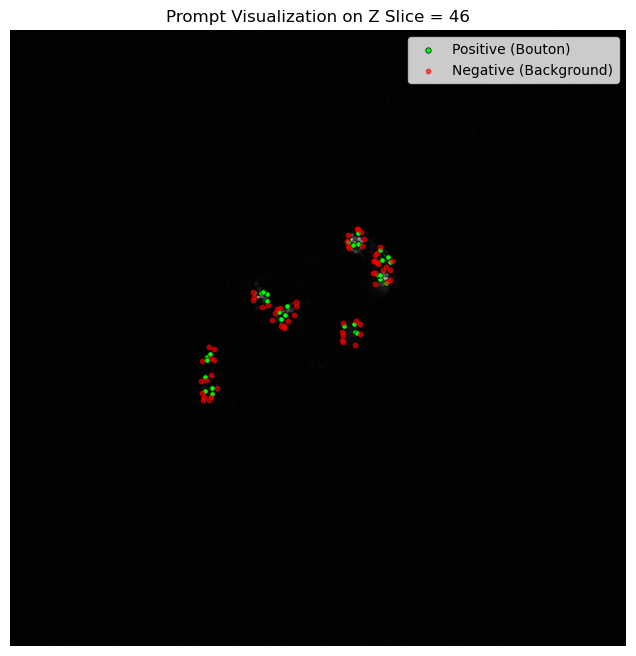

In [9]:

plt.figure(figsize=(8, 8))

# Show the image slice
if img_slice.ndim == 3:
    plt.imshow(img_slice[..., 0], cmap="gray")  # first channel
else:
    plt.imshow(img_slice, cmap="gray")

# POSITIVE points (smaller, green)
pos_pts = point_coords[point_labels == 1]
plt.scatter(
    pos_pts[:, 0], pos_pts[:, 1],
    c="lime", s=15, edgecolors="black", linewidths=0.5,
    label="Positive (Bouton)"
)

# NEGATIVE points (smaller, red)
neg_pts = point_coords[point_labels == 0]
plt.scatter(
    neg_pts[:, 0], neg_pts[:, 1],
    c="red", s=10, alpha=0.6,
    label="Negative (Background)"
)

plt.legend()
plt.title(f"Prompt Visualization on Z Slice = {z_index}")
plt.axis("off")
plt.show()
